### Analyzing Air Quality Index (AQI) Trends in a City

- dataset link : https://www.kaggle.com/code/yashvi/air-quality-analysis-of-delhi/data?select=city_day.csv

In [18]:
# Import the dataset
import pandas as pd 
import matplotlib.pyplot as plt


In [19]:
# Load the dataset
df = pd.read_csv("./datasets/assignment-10.csv")

print("Original DataFrame shape:", df.shape)

df.head()

Original DataFrame shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [20]:
# Explore the dataset

# Display column names
print("Columns:")
print(df.columns.tolist())

# Display dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check available locations
print("\nAvailable locations:")
print(df["City"].value_counts())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: flo

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000



Missing values:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

Available locations:
City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Mumbai                2009
Lucknow               2009
Delhi                 2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ko

In [ ]:
# Keep only records for ahemdabad
df = df[df["City"].str.strip().str.lower() == "ahmedabad"].copy()

# Convert date column to datetime format
df["Date"] = pd.to_datetime(df["Date"],errors='coerce')

columns=["PM2.5","PM10","CO","AQI"]
for col in columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df=df.dropna(subset=["Date"], how='any')
df = df.sort_values(by="Date")

print("Ahemdabad records",len(df))
display(df.head())

Ahemdabad records 2009


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
# Select one month (Choosen such that the null values of all the columns are minimised)
YEAR=2019
MONTH=6

monthly_df = df[(df["Date"].dt.year == YEAR) & (df["Date"].dt.month == MONTH)].copy()

print("Records in selected month:", len(monthly_df))
display(monthly_df)


Records in selected month: 30


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
1612,Ahmedabad,2019-06-01,48.10,142.06,23.83,70.71,61.67,NaN,23.83,142.52,40.22,15.50,84.08,12.18,467.0,Severe
1613,Ahmedabad,2019-06-02,41.38,119.91,21.80,70.35,59.18,NaN,21.80,134.76,41.50,15.90,83.78,14.01,402.0,Severe
1614,Ahmedabad,2019-06-03,46.46,134.20,22.33,74.31,61.71,NaN,22.33,137.83,47.63,14.50,81.45,10.98,419.0,Severe
1615,Ahmedabad,2019-06-04,39.68,117.51,20.89,77.12,61.44,NaN,20.89,139.31,71.62,12.58,79.02,7.46,408.0,Severe
1616,Ahmedabad,2019-06-05,38.27,113.84,18.87,61.74,51.63,NaN,18.87,112.15,82.73,115.14,371.65,NaN,402.0,Severe
1617,Ahmedabad,2019-06-06,35.06,127.56,12.63,68.94,48.03,NaN,12.63,101.14,75.71,26.24,85.15,94.48,303.0,Very Poor
1618,Ahmedabad,2019-06-07,30.07,124.01,15.49,122.88,78.85,NaN,15.49,31.67,70.29,NaN,NaN,NaN,354.0,Very Poor
1619,Ahmedabad,2019-06-08,48.74,135.90,16.38,154.42,94.00,NaN,16.38,58.60,73.95,7.29,80.04,2.05,358.0,Very Poor
1620,Ahmedabad,2019-06-09,35.30,120.77,15.20,146.65,88.87,NaN,15.20,127.62,81.55,29.46,141.33,14.86,324.0,Very Poor
1621,Ahmedabad,2019-06-10,34.31,115.46,16.31,127.02,80.56,NaN,16.31,121.46,80.39,26.90,256.09,56.49,360.0,Very Poor


In [28]:
# Prepare the data for plotting

plot_df = monthly_df.set_index("Date").sort_index()

print("Number of daily records:", len(plot_df))
print("Number of dates",plot_df.index.nunique())

display(plot_df[['AQI',"PM2.5","PM10","CO"]].head())

Number of daily records: 30
Number of dates 30


,AQI,PM2.5,PM10,CO
Date,,,,
2019-06-01,467.0,48.10,142.06,23.83
2019-06-02,402.0,41.38,119.91,21.80
2019-06-03,419.0,46.46,134.20,22.33
2019-06-04,408.0,39.68,117.51,20.89
2019-06-05,402.0,38.27,113.84,18.87


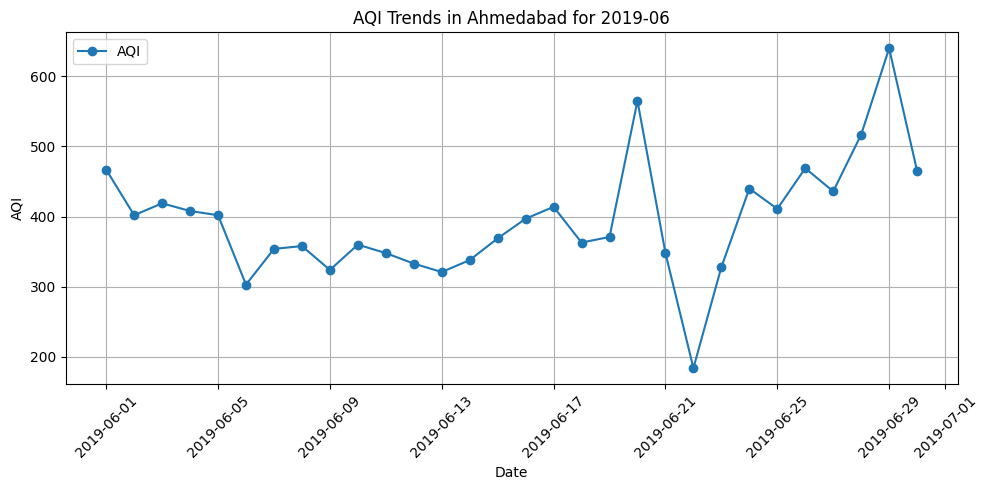

In [29]:
# Line plot for AQI trends
aqi_data = plot_df[['AQI']].dropna()

plt.figure(figsize=(10, 5))
plt.plot(aqi_data.index,aqi_data.values,marker="o",label="AQI")

plt.title(f"AQI Trends in Ahmedabad for {YEAR}-{MONTH:02d}")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

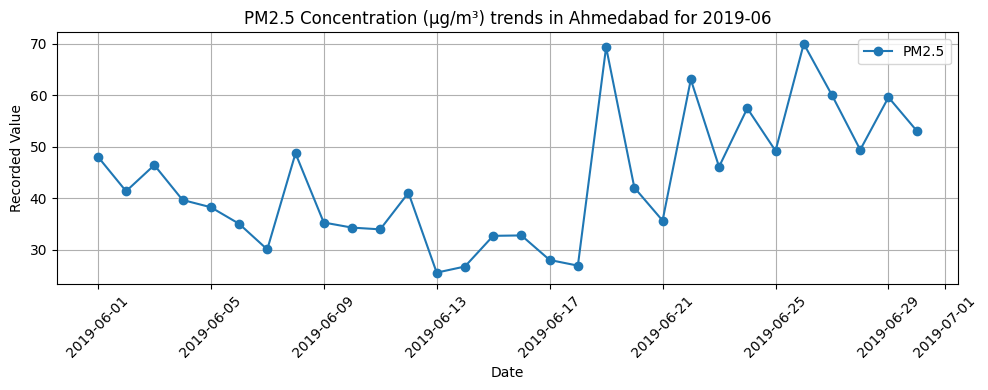

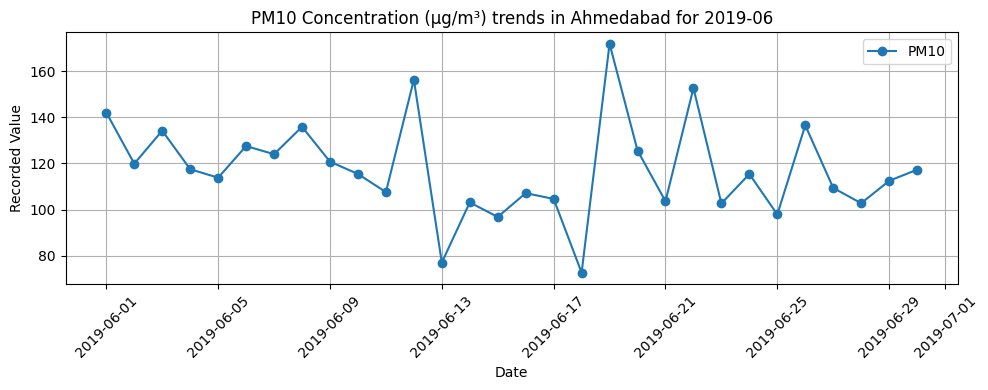

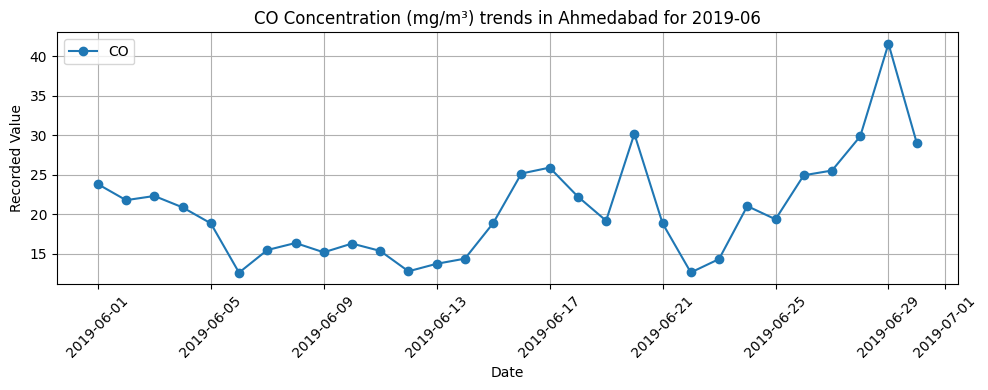

In [30]:
# Seperate line plots for pollutants

pollutants=[
    ("PM2.5", "PM2.5 Concentration (µg/m³)"),
    ("PM10", "PM10 Concentration (µg/m³)"),
    ("CO", "CO Concentration (mg/m³)")
]

for col,title in pollutants:
    data = plot_df[col].dropna()

    plt.figure(figsize=(10,4))
    plt.plot(data.index,data.values,marker="o",label=col)
    plt.title(f"{title} trends in Ahmedabad for {YEAR}-{MONTH:02d}")
    plt.xlabel("Date")
    plt.ylabel("Recorded Value")
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

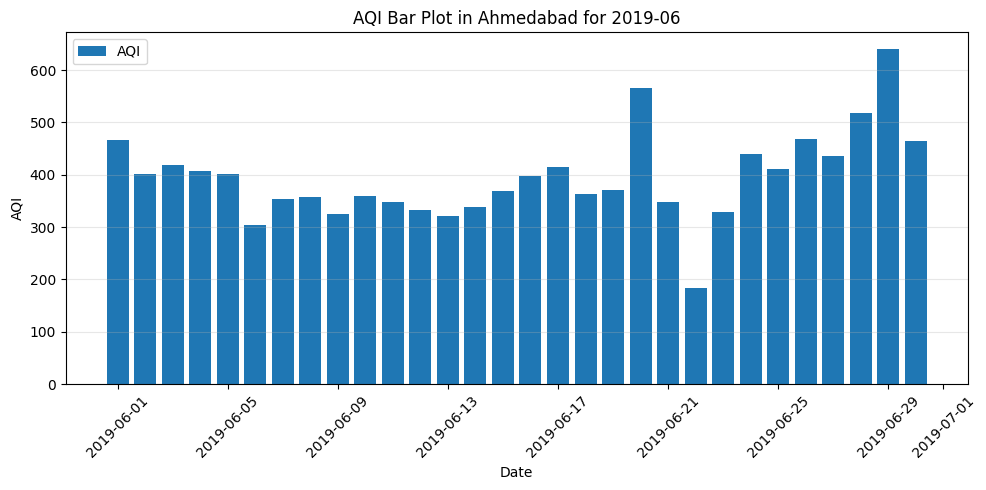

In [31]:
# Bar plot of AQI across dates
aqi_data = plot_df[['AQI']].dropna()

plt.figure(figsize=(10, 5))
plt.bar(aqi_data.index, aqi_data.values.flatten(),label="AQI")
plt.title(f"AQI Bar Plot in Ahmedabad for {YEAR}-{MONTH:02d}")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


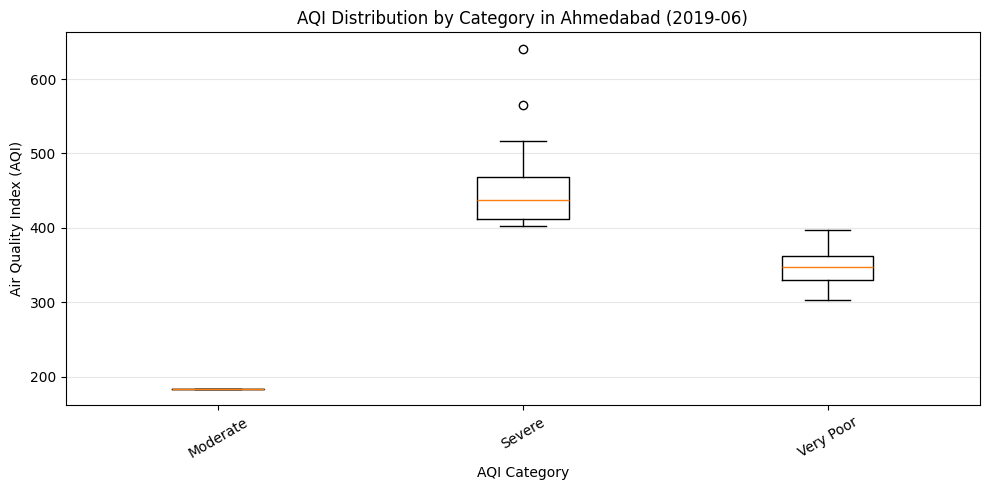

In [33]:
# Box plot of aqi by category

category_df = monthly_df.dropna(subset=["AQI","AQI_Bucket"])
if not category_df.empty:
    categories = sorted(category_df["AQI_Bucket"].unique())

    box_data=[
        category_df.loc[
            category_df["AQI_Bucket"]==cat,"AQI"
        ]
        for cat in categories
    ]

    plt.figure(figsize=(10, 5))
    plt.boxplot(box_data, tick_labels=categories)

    plt.title(f"AQI Distribution by Category in Ahmedabad ({YEAR}-{MONTH:02d})")
    plt.xlabel("AQI Category")
    plt.ylabel("Air Quality Index (AQI)")
    plt.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No data available for AQI distribution by category in the selected month.")


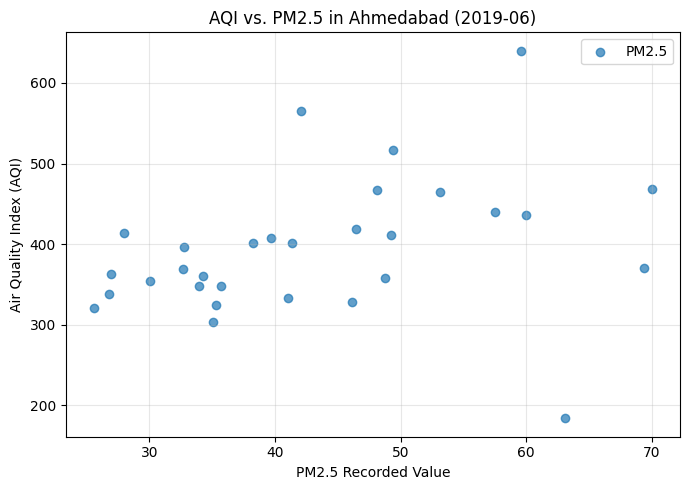

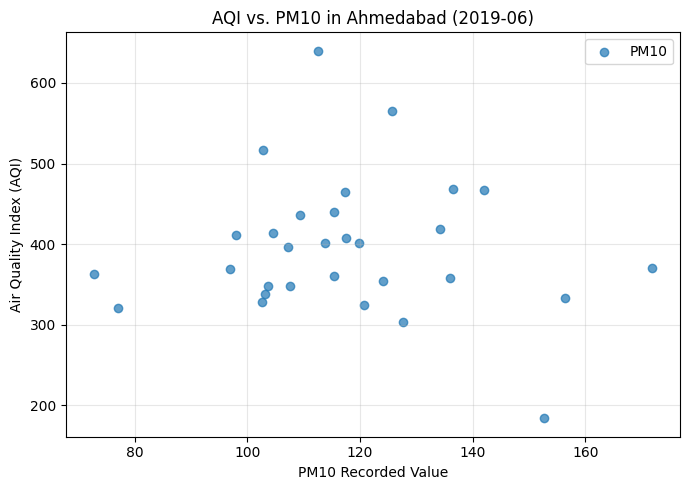

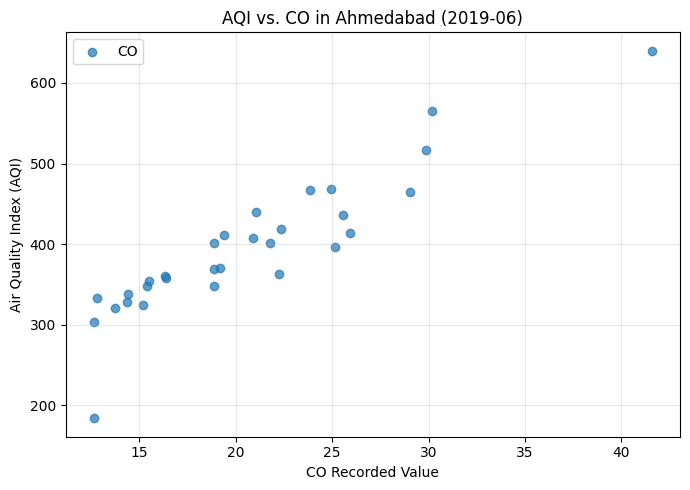

In [34]:
# Scatter plot of AQI vs pollutants

pollutants = [
    ("PM2.5", "PM2.5"),
    ("PM10", "PM10"),
    ("CO", "CO")
]

for col, label in pollutants:
    data = monthly_df.dropna(subset=["AQI", col])

    if not data.empty:
        plt.figure(figsize=(7, 5))
        plt.scatter(data[col], data["AQI"],
                    alpha=0.7, label=label)

        plt.title(f"AQI vs. {label} in Ahmedabad ({YEAR}-{MONTH:02d})")
        plt.xlabel(f"{label} Recorded Value")
        plt.ylabel("Air Quality Index (AQI)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No valid AQI and {label} data available.")

In [35]:
# Summary (Monthly AQI Data for Ahmedabad)

print(f"AIR QUALITY ANALYSIS: AHMEDABAD ({YEAR}-{MONTH:02d})")
print("-" * 50)

print("Total records:", len(monthly_df))
print("Records with AQI:", monthly_df["AQI"].count())

print("\nAQI statistics:")
print(monthly_df["AQI"].describe())

print("\nPollutant statistics:")
print(monthly_df[["PM2.5", "PM10", "CO"]].describe())

print("\nAQI category counts:")
print(monthly_df["AQI_Bucket"].value_counts(dropna=False))

AIR QUALITY ANALYSIS: AHMEDABAD (2019-06)
--------------------------------------------------
Total records: 30
Records with AQI: 30

AQI statistics:
count     30.000000
mean     395.133333
std       85.216047
min      184.000000
25%      348.000000
50%      384.000000
75%      431.750000
max      640.000000
Name: AQI, dtype: float64

Pollutant statistics:
           PM2.5        PM10         CO
count  30.000000   30.000000  30.000000
mean   43.349667  117.498667  20.633667
std    12.688132   21.400559   6.549540
min    25.560000   72.700000  12.630000
25%    34.055000  103.890000  15.407500
50%    41.230000  115.440000  19.290000
75%    49.380000  127.075000  24.670000
max    70.030000  171.870000  41.590000

AQI category counts:
AQI_Bucket
Very Poor    15
Severe       14
Moderate      1
Name: count, dtype: int64
